# Task Orbit: ML dataset, training and evaluation

This notebook documents the three models behind Task Orbit (PLAN_V2 section 6):

| Model | Predicts | Compared with |
|---|---|---|
| **A. Overload classifier** | low / medium / high load for each of the next 7 days | the rule engine (hours ÷ available hours) |
| **B. Time estimator** | the real hours a task will take | the student's own estimate |
| **C. Late-submission risk** | probability a teacher task is submitted late | the rule-based early-warning score |

**Data honesty:** all numbers here come from a **synthetic** dataset (`ml/generate_dataset.py`), not from real
students. Real classmate data (weekly check-ins + logged hours) should be reported separately once collected.

Run order: `python -m ml.generate_dataset` → `python -m ml.train` → this notebook.

In [1]:
import json, sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, f1_score, mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit

BACKEND = Path.cwd().parent / "backend"
sys.path.insert(0, str(BACKEND))
DATA, ART = BACKEND / "ml" / "data", BACKEND / "ml" / "artifacts"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
metrics = json.loads((ART / "metrics.json").read_text())
print("Model version:", metrics["model_version"], "| split:", metrics["split"])

Model version: v1-20261103 | split: 80/20 by student (GroupShuffleSplit), 5-fold GroupKFold CV


## 1. The synthetic dataset

`generate_dataset.py` simulates **300 students in 10 classes over 12 weeks**. Each class has 3 subjects whose teachers post
work independently, so deadlines cluster like they do in real semesters. Every student has hidden traits the app never sees:

* **speed**: real hours ÷ estimated hours (log-normal, mean ≈ 1.12, some students ≈ 2×),
* **procrastination**: how late they start,
* **disruptions**: random days with much less study time than planned.

Features use only what the app can see (estimates, availability, history). Labels use the hidden reality.
That gap is what the models must learn.

Model A rows: 71,400 | Model B rows: 14,111 | Model C rows: 9,456
Students: 300


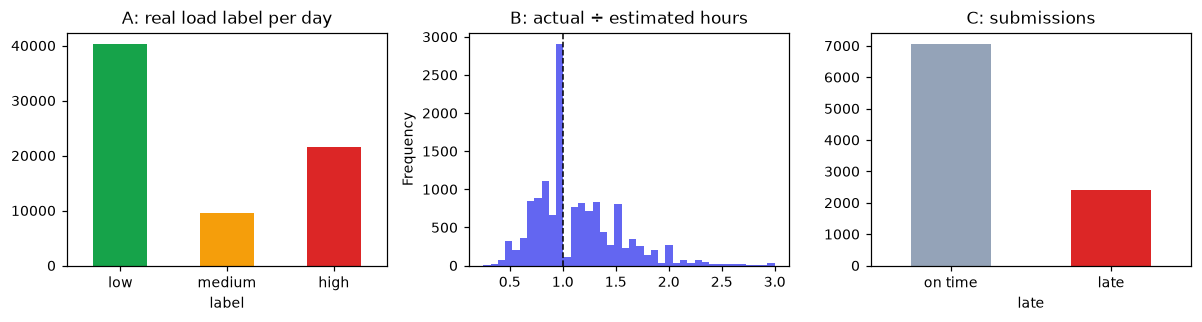

In [2]:
overload = pd.read_csv(DATA / "overload.csv")
time_df = pd.read_csv(DATA / "time.csv")
risk = pd.read_csv(DATA / "risk.csv")
print(f"Model A rows: {len(overload):,} | Model B rows: {len(time_df):,} | Model C rows: {len(risk):,}")
print("Students:", overload.student_id.nunique())

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
overload.label.value_counts().reindex(["low", "medium", "high"]).plot.bar(ax=axes[0], color=["#16a34a", "#f59e0b", "#dc2626"])
axes[0].set_title("A: real load label per day")
(time_df.actual_hours / time_df.estimated_hours).clip(0, 3).plot.hist(bins=40, ax=axes[1], color="#6366f1")
axes[1].axvline(1, color="k", ls="--", lw=1)
axes[1].set_title("B: actual ÷ estimated hours")
risk.late.map({0: "on time", 1: "late"}).value_counts().plot.bar(ax=axes[2], color=["#94a3b8", "#dc2626"])
axes[2].set_title("C: submissions")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

Students under-estimate on average (most of the histogram is right of 1.0). That is the main reason the
plain rule engine, which trusts the estimates, misses real overload.

## 2. Training

`train.py` compares **Logistic Regression, Random Forest and Gradient Boosting** with 5-fold `GroupKFold`
cross-validation on the training students, picks the best, and evaluates it once on **held-out students**
(80/20 `GroupShuffleSplit` by student, so no student is in both sets). Forests are capped at 100 trees so the
models stay small for the free server.

In [3]:
rows = []
for key, metric in [("overload", "cv_macro_f1"), ("time", "cv_neg_mae"), ("risk", "cv_macro_f1")]:
    for model, score in metrics[key][metric].items():
        rows.append({"model": key, "algorithm": model, metric.replace("cv_", "CV "): score,
                     "chosen": "✔" if model == metrics[key]["model"] else ""})
pd.DataFrame(rows).astype(object).fillna("")

,model,algorithm,CV macro_f1,chosen,CV neg_mae
0,overload,logistic_regression,0.7512,✔,
1,overload,random_forest,0.749,,
2,overload,gradient_boosting,0.7507,,
3,time,ridge,,,-0.9409
4,time,random_forest,,,-0.7948
5,time,gradient_boosting,,✔,-0.7903
6,risk,logistic_regression,0.5969,✔,
7,risk,random_forest,0.5954,,
8,risk,gradient_boosting,0.5341,,


In [4]:
sizes = {p.name: f"{p.stat().st_size / 1e6:.2f} MB" for p in ART.glob("*.joblib")}
sizes

{'overload_clf.joblib': '0.00 MB',
 'risk_clf.joblib': '0.00 MB',
 'time_reg.joblib': '0.04 MB'}

## 3. Evaluation on held-out students

### Model A: overload classifier vs rules

macro-F1  ML 0.749  |  rules 0.698  |  improvement +5.1 points


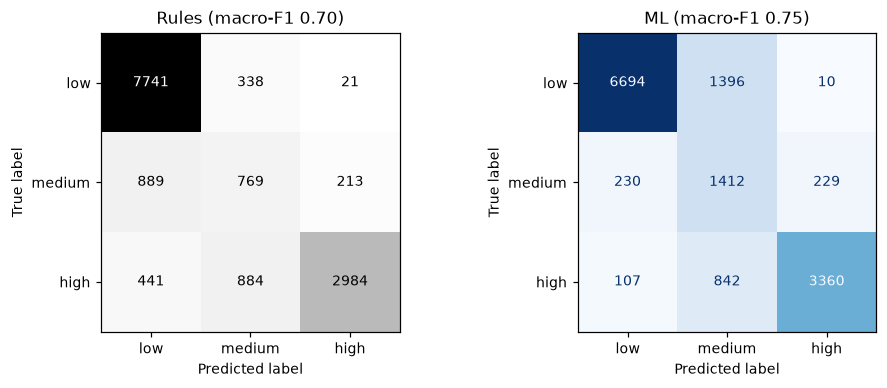

In [5]:
def test_split(df):
    _, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(df, groups=df.student_id))
    return df.iloc[te]

bundle = joblib.load(ART / "overload_clf.joblib")
test = test_split(overload)
pred = bundle["model"].predict(test[bundle["features"]])
labels = ["low", "medium", "high"]
ml_f1, rule_f1 = f1_score(test.label, pred, average="macro"), f1_score(test.label, test.rule_label, average="macro")
print(f"macro-F1  ML {ml_f1:.3f}  |  rules {rule_f1:.3f}  |  improvement {100 * (ml_f1 - rule_f1):+.1f} points")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay.from_predictions(test.label, test.rule_label, labels=labels, ax=axes[0], colorbar=False, cmap="Greys")
axes[0].set_title(f"Rules (macro-F1 {rule_f1:.2f})")
ConfusionMatrixDisplay.from_predictions(test.label, pred, labels=labels, ax=axes[1], colorbar=False, cmap="Blues")
axes[1].set_title(f"ML (macro-F1 {ml_f1:.2f})")
plt.tight_layout(); plt.show()

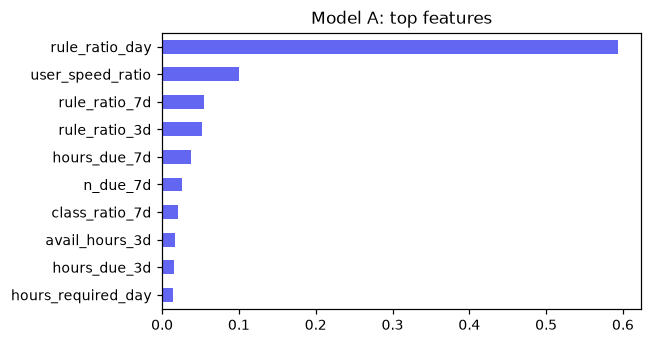

In [6]:
imp = pd.Series(metrics["overload"]["feature_importance"]).head(10)[::-1]
imp.plot.barh(color="#6366f1", figsize=(6, 3.2), title="Model A: top features"); plt.tight_layout(); plt.show()

The rule engine's own ratio stays the strongest signal, but `user_speed_ratio` (how much longer this student usually
takes) lets the model catch days that look fine on paper but are not, which is where the rules under-predict *high*.

### Model B: time estimator vs the student's own estimate

MAE  student estimate 1.22 h  ->  ML 0.76 h  (38% lower)
  tasks where 5+ classmates finished (n=1576): MAE 1.21 h without their hours -> 0.84 h with them


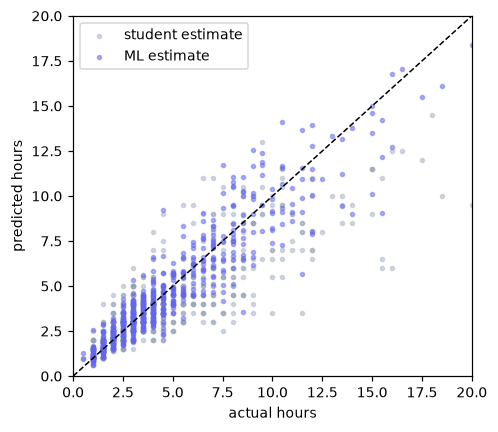

In [7]:
bundle = joblib.load(ART / "time_reg.joblib")
test = test_split(time_df)
pred = bundle["model"].predict(test[bundle["features"]])
raw_mae, ml_mae = mean_absolute_error(test.actual_hours, test.estimated_hours), mean_absolute_error(test.actual_hours, pred)
print(f"MAE  student estimate {raw_mae:.2f} h  ->  ML {ml_mae:.2f} h  ({100 * (1 - ml_mae / raw_mae):.0f}% lower)")

# Fair test of the classmate signal: the SAME assignment rows, predicted with and without it.
rows = test[test.class_done >= 5]
blind = rows.assign(class_avg_ratio=1.0, class_done=0)
with_class = mean_absolute_error(rows.actual_hours, bundle["model"].predict(rows[bundle["features"]]))
without = mean_absolute_error(rows.actual_hours, bundle["model"].predict(blind[bundle["features"]]))
print(f"  tasks where 5+ classmates finished (n={len(rows)}): MAE {without:.2f} h without their hours -> {with_class:.2f} h with them")

s = test.assign(pred=pred).sample(700, random_state=1)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.scatter(s.actual_hours, s.estimated_hours, s=7, alpha=.4, color="#94a3b8", label="student estimate")
ax.scatter(s.actual_hours, s.pred, s=7, alpha=.5, color="#6366f1", label="ML estimate")
ax.plot([0, 20], [0, 20], "k--", lw=1); ax.set_xlim(0, 20); ax.set_ylim(0, 20)
ax.set_xlabel("actual hours"); ax.set_ylabel("predicted hours"); ax.legend(); plt.tight_layout(); plt.show()

The second line is the fair test of classmates' real hours on the same assignment (`class_avg_ratio`): the
same tasks predicted with and without that signal. Whatever the gain is, report it as measured. This
"crowd-calibrated estimate" is something a single-student app cannot do.

### Model C: late-submission risk vs the rule-based score

late rate 26% | macro-F1 ML 0.628 vs rules 0.437 (+19.2 points)
Thresholds used in the app (high >= 0.60, medium >= 0.50):
  >= 0.5: flags 38% of tasks, 42% of those are really late (base rate 26%), catches 61% of late tasks
  >= 0.6: flags 22% of tasks, 50% of those are really late (base rate 26%), catches 43% of late tasks


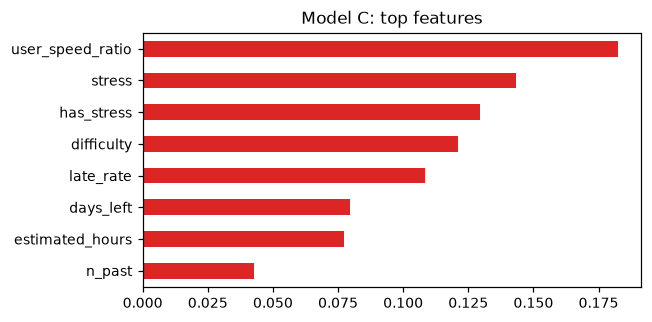

In [8]:
bundle = joblib.load(ART / "risk_clf.joblib")
test = test_split(risk)
proba = bundle["model"].predict_proba(test[bundle["features"]])[:, 1]
m = metrics["risk"]
print(f"late rate {test.late.mean():.0%} | macro-F1 ML {m['ml']['macro_f1']:.3f} vs rules {m['rules']['macro_f1']:.3f} "
      f"({m['improvement_macro_f1_points']:+.1f} points)")
print("Thresholds used in the app (high >= 0.60, medium >= 0.50):")  # chosen on these held-out students
for th in [0.5, 0.6]:
    flagged = proba >= th
    print(f"  >= {th}: flags {flagged.mean():.0%} of tasks, {test.late[flagged].mean():.0%} of those are really late "
          f"(base rate {test.late.mean():.0%}), catches {test.late[flagged].sum() / test.late.sum():.0%} of late tasks")
pd.Series(m["feature_importance"]).head(8)[::-1].plot.barh(color="#dc2626", figsize=(6, 3), title="Model C: top features")
plt.tight_layout(); plt.show()

## 4. Results against the objectives (SPEC section 2)

| Objective | Target | Result |
|---|---|---|
| Overload classifier macro-F1 on held-out students | ≥ 0.80 | see table below |
| ML beats rule-only baseline | ≥ +5 macro-F1 points | see table below |
| Time estimator cuts MAE vs raw estimate | ≥ 15 % | see table below |

In [9]:
pd.DataFrame([
    {"objective": "A macro-F1 >= 0.80", "result": metrics["overload"]["ml"]["macro_f1"],
     "met": metrics["overload"]["ml"]["macro_f1"] >= 0.80},
    {"objective": "A beats rules by >= 5 pts", "result": metrics["overload"]["improvement_macro_f1_points"],
     "met": metrics["overload"]["improvement_macro_f1_points"] >= 5},
    {"objective": "B MAE reduction >= 15%", "result": metrics["time"]["mae_reduction_pct"],
     "met": metrics["time"]["mae_reduction_pct"] >= 15},
    {"objective": "C beats rules (macro-F1 pts)", "result": metrics["risk"]["improvement_macro_f1_points"],
     "met": metrics["risk"]["improvement_macro_f1_points"] > 0},
])

,objective,result,met
0,A macro-F1 >= 0.80,0.7487,False
1,A beats rules by >= 5 pts,5.1000,True
2,B MAE reduction >= 15%,37.7000,True
3,C beats rules (macro-F1 pts),19.2000,True


## 5. Limitations (state these in the report)

* **Synthetic data.** The simulator encodes our assumptions (log-normal speed, procrastination, disruptions). Good scores
  show the pipeline works and that the features carry signal; they are **not** proof of real-world accuracy.
* **Model A misses the 0.80 target** (≈ 0.75 macro-F1) on the realistic simulation, while still beating the rules by
  ≈ 5 points. Its errors come from things no feature can see in advance: disrupted days and assignments that turn out
  harder than the teacher expected. An earlier, simpler simulation without per-assignment surprises reached 0.81; we
  report the harder, more realistic result.
* **Model C is modest** (macro-F1 ≈ 0.6). Lateness depends on things the app cannot see. It is useful for *ranking*
  students to check on, not as a verdict, which is why the UI always shows the reasons next to the score.
* **Next step:** collect real data from 20–30 classmates (logged actual hours, weekly stress check-ins, on-time vs late),
  report it separately, and retrain with `train.py`. Every completed task in the app already stores the label needed.